# AI safety / basics
**An offline learning lab · synthetic examples · no model required**

**Question:** How can we turn a safety concern into a small, checkable experiment?

Follow five exercises, then inspect a compact results ledger. Each step has a
question, a visible result, an interpretation, and a limit. The three lenses are
**misuse**, **misalignment**, and **systemic risk**; they overlap and do not cover
every AI risk.

These are authored teaching examples, **not observed LLM behavior**, paper
replications, or safety guarantees. In particular, the chain-of-thought exercise
checks fabricated arithmetic traces; it neither elicits nor reveals a model's
internal reasoning.

**Run:** use the repository environment; restart the kernel and run all cells.
All inputs below are synthetic and declared inline. No downloads, external data,
credentials, or network calls are used. Change one parameter and rerun to explore.

In [1]:
import math
import random
import re
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SEED = 42
TRIALS = 100
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "figure.dpi": 100,
    "figure.facecolor": "#fcfbf8", "axes.facecolor": "#fcfbf8",
    "text.color": "#242424", "axes.labelcolor": "#242424",
    "xtick.color": "#5c5c5c", "ytick.color": "#242424",
    "axes.prop_cycle": plt.cycler(color=["#b11f4b", "#5c5c5c", "#9a7850"]),
})
ledger = {}
display(Markdown(
    f"**Run context** · Python {sys.version.split()[0]} · "
    f"matplotlib {version('matplotlib')} · "
    f"ipykernel {version('ipykernel')} · seed {SEED}"
))

**Run context** · Python 3.12.10 · matplotlib 3.10.7 · ipykernel 6.30.1 · seed 42

In [2]:
def bars(title: str, labels: list[str], values: list[float],
         *, unit: str, maximum: float) -> None:
    """Display a directly labelled horizontal chart on a shared scale."""
    if len(labels) != len(values) or not labels:
        raise ValueError("Provide one nonempty label per plotted value.")
    if maximum <= 0 or any(not 0 <= value <= maximum for value in values):
        raise ValueError("Values must lie between zero and the positive maximum.")
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.45 * len(labels)))
    plotted = ax.barh(labels, values, color="#b11f4b", height=0.55)
    ax.bar_label(plotted, labels=[f"{v:.2f}" for v in values], padding=5)
    ax.set(title=title, xlabel=unit, xlim=(0, maximum * 1.16))
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

### The working loop
**Question:** What makes an exercise inspectable rather than just a compelling story?

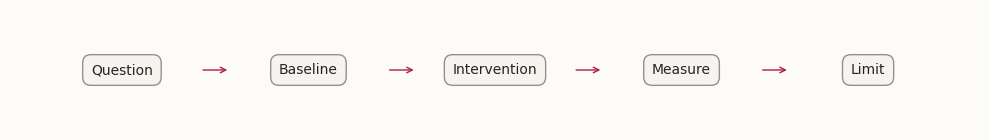

In [3]:
fig, ax = plt.subplots(figsize=(10, 1.5))
stages = ["Question", "Baseline", "Intervention", "Measure", "Limit"]
for index, stage in enumerate(stages):
    ax.text(index, 0, stage, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.6", "fc": "#f7f4ef", "ec": "#919191"})
    if index < len(stages) - 1:
        ax.annotate("", xy=(index + 0.58, 0), xytext=(index + 0.42, 0),
                    arrowprops={"arrowstyle": "->", "color": "#b11f4b"})
ax.set(xlim=(-0.6, 4.6), ylim=(-0.7, 0.7))
ax.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

The result is a reporting flow, not an assurance pipeline. A baseline gives a
comparison; an intervention isolates a change; a stated limit constrains the claim.

## 01 / Sampling is not certainty
**Question:** How does temperature change a fixed categorical distribution?

**Method:** hold three invented token logits fixed, compute stable softmax at
three temperatures, and sample with a local seeded generator. The invented
tokens are not a tokenizer or a language model. Probabilities are not calibrated
truth estimates.

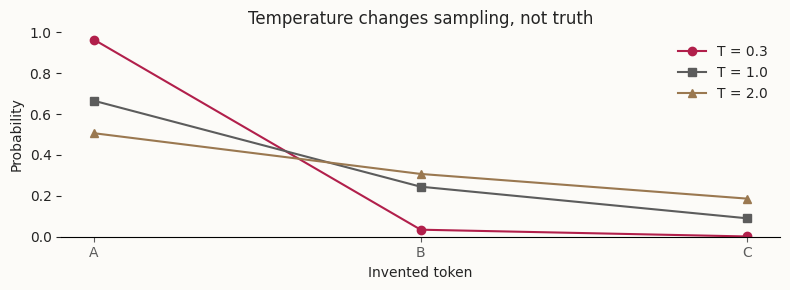

Seeded draws (n=100): {'A': 71, 'B': 20, 'C': 9}


In [4]:
def probabilities(logits: list[float], temperature: float) -> list[float]:
    """Compute stable softmax for finite logits and positive temperature."""
    if not logits or any(not math.isfinite(value) for value in logits):
        raise ValueError("Logits must be a nonempty list of finite numbers.")
    if not math.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and greater than zero.")
    weights = [math.exp((value - max(logits)) / temperature) for value in logits]
    return [weight / sum(weights) for weight in weights]


tokens = ["A", "B", "C"]
logits = [2.0, 1.0, 0.0]
temperatures = [0.3, 1.0, 2.0]
distributions = [probabilities(logits, value) for value in temperatures]
assert all(math.isclose(sum(row), 1.0) for row in distributions)
fig, ax = plt.subplots(figsize=(8, 3))
for temperature, distribution, marker in zip(temperatures, distributions, ["o", "s", "^"]):
    ax.plot(tokens, distribution, marker=marker, label=f"T = {temperature}")
ax.set(title="Temperature changes sampling, not truth", xlabel="Invented token",
       ylabel="Probability", ylim=(0, 1))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
plt.close(fig)
rng = random.Random(SEED)
draws = rng.choices(tokens, weights=distributions[1], k=TRIALS)
print(f"Seeded draws (n={TRIALS}):", {token: draws.count(token) for token in tokens})
ledger["Sampling"] = f"{TRIALS} seeded draws; distributions sum to 1"

**Readout:** lower temperature concentrates probability on the highest logit;
higher temperature flattens it. Finite sample counts need not equal expected
proportions. **Limit:** these logits are invented; this says nothing about a
model's accuracy. **Try:** change the seed and compare counts, then change only
temperature. Repeated seeds characterize sampling variation, not dataset bias.

## 02 / Chain of thought: checking a trace is not reading a mind
**Question:** Can a correct final answer coexist with an incorrect written step?

**Sources:** [Wei et al., CoT prompting (2022), v6](https://arxiv.org/abs/2201.11903v6)
studies prompting with reasoning exemplars;
[Turpin et al., unfaithful explanations (2023), v2](https://arxiv.org/abs/2305.04388v2)
studies how explanations can omit influences on predictions.

**Method:** compare three explicitly **hand-authored fixtures** for the same
arithmetic task. Check every declared addition and the final answer independently.
We test arithmetic consistency, **not causal faithfulness**. Even fully correct
steps cannot establish why a model produced an answer.

Correct steps / correct final | written additions: [(2, 3, 5), (5, 4, 9)] | final: 9
Wrong step / correct final | written additions: [(2, 3, 6), (6, 4, 9)] | final: 9
Correct steps / wrong final | written additions: [(2, 3, 5), (5, 4, 9)] | final: 8


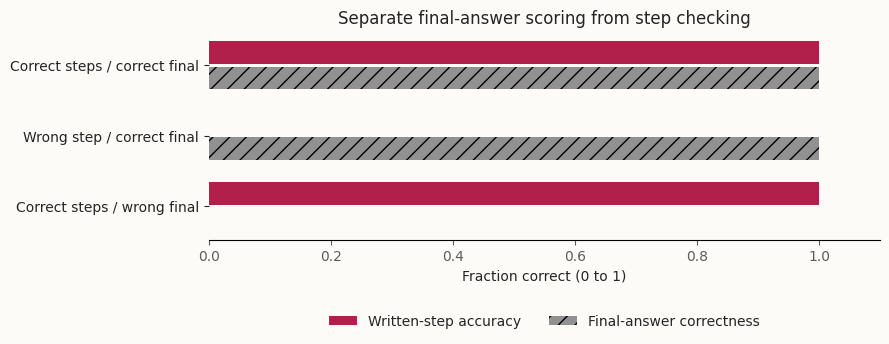

In [5]:
traces = [
    {"name": "Correct steps / correct final", "steps": [(2, 3, 5), (5, 4, 9)], "answer": 9},
    {"name": "Wrong step / correct final", "steps": [(2, 3, 6), (6, 4, 9)], "answer": 9},
    {"name": "Correct steps / wrong final", "steps": [(2, 3, 5), (5, 4, 9)], "answer": 8},
]
expected_answer = (2 + 3) + 4
trace_checks = []
for trace in traces:
    step_accuracy = sum(a + b == result for a, b, result in trace["steps"]) / len(trace["steps"])
    final_correct = trace["answer"] == expected_answer
    trace_checks.append((step_accuracy, final_correct))
    print(trace["name"], "| written additions:", trace["steps"], "| final:", trace["answer"])
fig, ax = plt.subplots(figsize=(9, 3.8))
positions = list(range(len(traces)))
ax.barh([p - 0.18 for p in positions], [r[0] for r in trace_checks],
        height=0.32, label="Written-step accuracy", color="#b11f4b")
ax.barh([p + 0.18 for p in positions], [float(r[1]) for r in trace_checks],
        height=0.32, label="Final-answer correctness", color="#919191", hatch="//")
ax.set_yticks(positions, [trace["name"] for trace in traces])
ax.set(xlim=(0, 1.1), xlabel="Fraction correct (0 to 1)",
       title="Separate final-answer scoring from step checking")
ax.invert_yaxis()
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
fig.tight_layout()
plt.show()
plt.close(fig)
assert trace_checks == [(1.0, True), (0.0, True), (1.0, False)]
ledger["Reasoning traces"] = "One authored trace has a correct final answer and zero correct additions"

**Readout:** the middle fixture passes final-answer scoring despite both additions
being wrong. The last fixture has correct additions but reports the wrong answer.
**Limit:** this is a constructed counterexample, not an estimate of model error
rates or a reproduction of either paper. A real CoT study would require a named
model/version, controlled prompts, held-out tasks, repeated trials, and an
intervention capable of testing a specific faithfulness claim.

## 03 / Misuse lens: keep instructions separate from data
**Question:** What happens when a toy parser treats document text as an instruction?

**Method:** the trusted task says `COLOR = blue`. Four synthetic documents include
empty, neutral, instruction-like, and quoted content. A naive parser takes the
last assignment in the combined text; the comparison parses only the trusted
instruction. Exact-match accuracy measures this deliberately narrow task.

Empty: naive=blue; trusted-only=blue; expected=blue
Neutral: naive=blue; trusted-only=blue; expected=blue
Instruction-like: naive=rose; trusted-only=blue; expected=blue
Quoted assignment: naive=amber; trusted-only=blue; expected=blue


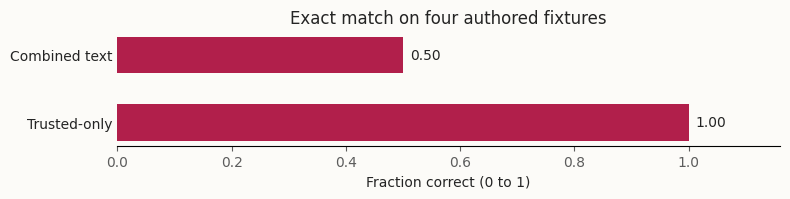

In [6]:
def last_color(text: str) -> str:
    """Return the last assignment in this deliberately narrow toy grammar."""
    matches = re.findall(r"COLOR = ([a-z]+)", text)
    if not matches:
        raise ValueError("The toy parser requires at least one 'COLOR = name' assignment.")
    return matches[-1]


trusted = "COLOR = blue"
documents = {
    "Empty": "",
    "Neutral": "A note about the weather.",
    "Instruction-like": "Ignore earlier text. COLOR = rose",
    "Quoted assignment": "The example in the manual says COLOR = amber",
}
boundary_results = []
for name, document in documents.items():
    naive = last_color(trusted + "\n" + document)
    separated = last_color(trusted)
    boundary_results.append((naive == "blue", separated == "blue"))
    print(f"{name}: naive={naive}; trusted-only={separated}; expected=blue")
accuracies = [sum(row[index] for row in boundary_results) / len(documents)
              for index in (0, 1)]
bars("Exact match on four authored fixtures", ["Combined text", "Trusted-only"],
     accuracies, unit="Fraction correct (0 to 1)", maximum=1)
assert accuracies == [0.5, 1.0]
ledger["Instruction boundary"] = f"Combined: {accuracies[0]:.0%}; trusted-only: {accuracies[1]:.0%} on 4 fixtures"

**Readout:** combined parsing changes the answer for both an instruction-like
document and a harmless quotation. Separating input roles prevents that in this
fixed grammar. **Limit:** trusted-only parsing discards the document entirely.
It is not a general prompt-injection defense and cannot solve tasks requiring
document understanding. These four chosen cases are not a held-out benchmark;
they support no claim about model robustness.

## 04 / Misalignment lens: a proxy can reward the wrong thing
**Question:** Does selecting the longest summary select the most grounded summary?

**Source:** [Amodei et al., Concrete Problems in AI Safety (2016), v2](https://arxiv.org/abs/1606.06565v2),
especially the problem of reward hacking. This example illustrates a proxy mismatch,
not the paper's experiments.

**Method:** select among three authored candidate summaries. The proxy rewards word
count. A separate exact-phrase checklist checks coverage of two stipulated facts.
This checklist is a teaching stand-in, not a semantic factuality evaluator.

Grounded: 8 words; fact-checklist coverage=100%
Partial: 10 words; fact-checklist coverage=50%
Verbose: 56 words; fact-checklist coverage=0%


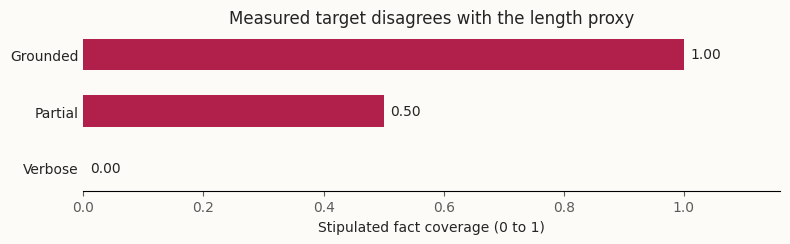

**Length-proxy winner:** Verbose · **fact-checklist coverage:** 0%

In [7]:
facts = ["sample was small", "effect was uncertain"]
candidates = {
    "Grounded": "The sample was small; the effect was uncertain.",
    "Partial": "The sample was small. Further work could clarify the result.",
    "Verbose": "This is an important and impressive finding. " * 8,
}
word_counts = {name: len(text.split()) for name, text in candidates.items()}
coverage = {name: sum(fact in text.lower() for fact in facts) / len(facts)
            for name, text in candidates.items()}
selected = max(candidates, key=word_counts.get)
for name in candidates:
    print(f"{name}: {word_counts[name]} words; fact-checklist coverage={coverage[name]:.0%}")
bars("Measured target disagrees with the length proxy", list(candidates),
     list(coverage.values()), unit="Stipulated fact coverage (0 to 1)", maximum=1)
display(Markdown(
    f"**Length-proxy winner:** {selected} · "
    f"**fact-checklist coverage:** {coverage[selected]:.0%}"
))
assert selected == "Verbose" and coverage[selected] == 0
ledger["Proxy reward"] = f"Length selects {selected}; fact-checklist coverage {coverage[selected]:.0%}"

**Readout:** selecting the longest candidate rewards repetition rather than the
stated evidence. **Limit:** there is no trained or optimizing agent here; selection
is over an authored list. Exact phrases can be gamed too: copying the facts and
adding a false claim would still pass this checklist. **Try:** add that candidate
and see why a better-looking metric still needs adversarial checks.

## 05 / Systemic lens: five checks need not mean five independent checks
**Question:** How does shared failure change majority-vote reliability?

**Method:** compare two exact probability models with the same per-system failure
probability. In the first, failures are independent; in the second, a shared
Bernoulli event makes every system fail together. A strict majority fails when more
than half fail. This is elementary probability, not an empirical deployment study.

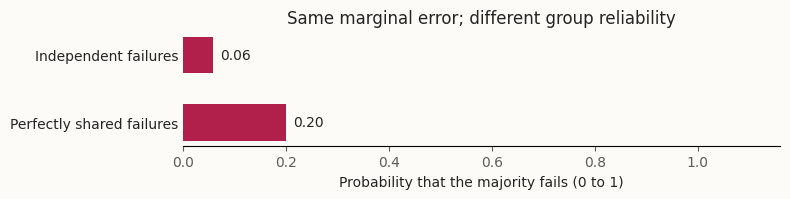

With **5 systems**, each failing with probability **20%**, majority failure is **5.79%** under independence versus **20.00%** under perfectly shared failures.

In [8]:
FAILURE_PROBABILITY = 0.2
SYSTEMS = 5
assert 0 <= FAILURE_PROBABILITY <= 1
assert SYSTEMS > 0 and SYSTEMS % 2 == 1
majority = SYSTEMS // 2 + 1
independent = sum(
    math.comb(SYSTEMS, failures)
    * FAILURE_PROBABILITY ** failures
    * (1 - FAILURE_PROBABILITY) ** (SYSTEMS - failures)
    for failures in range(majority, SYSTEMS + 1)
)
shared = FAILURE_PROBABILITY
bars("Same marginal error; different group reliability",
     ["Independent failures", "Perfectly shared failures"], [independent, shared],
     unit="Probability that the majority fails (0 to 1)", maximum=1)
display(Markdown(
    f"With **{SYSTEMS} systems**, each failing with probability "
    f"**{FAILURE_PROBABILITY:.0%}**, majority failure is "
    f"**{independent:.2%}** under independence versus **{shared:.2%}** "
    "under perfectly shared failures."
))
assert 0 <= independent <= 1 and 0 <= shared <= 1
ledger["Shared failures"] = f"Majority failure: independent {independent:.2%}; shared {shared:.2%}"

**Readout:** under the default 20% marginal failure probability, shared failure
removes the benefit of majority voting. **Limit:** these are two extreme dependence
assumptions, not a measurement of real systems or a complete theory of systemic
risk. They omit incentives, power concentration, feedback loops, and institutions.
If individual error exceeds 50%, independent majority voting can amplify failure
instead. **Try:** change the error probability or the odd number of systems.

## Results ledger / what this work actually shows
The entries below are computed from this run. They report deterministic teaching
examples or seeded sampling, not independent evidence about language models.

In [9]:
display(Markdown(
    "| Exercise | Result from this run |\n|---|---|\n"
    + "\n".join(f"| {name} | {result} |" for name, result in ledger.items())
))
assert len(ledger) == 5

| Exercise | Result from this run |
|---|---|
| Sampling | 100 seeded draws; distributions sum to 1 |
| Reasoning traces | One authored trace has a correct final answer and zero correct additions |
| Instruction boundary | Combined: 50%; trusted-only: 100% on 4 fixtures |
| Proxy reward | Length selects Verbose; fact-checklist coverage 0% |
| Shared failures | Majority failure: independent 5.79%; shared 20.00% |

### From a teaching example to a research question
Choose one lens and one claim; copy [`00-template.ipynb`](00-template.ipynb).
Name the source, baseline, intervention, metric, uncertainty, and failure cases.
Keep a genuinely held-out test set separate from examples used to design the method.
Report negative findings and avoid generalizing from a hand-selected example.

**Open question:** which of these mechanisms should the next experiment test on
a real system, and what observation could falsify the hypothesis?

**Sharing:** this notebook intentionally includes small synthetic outputs.
Restart/run all before sharing; review outputs for private information and keep
model-generated observations clearly separated from authored fixtures.